# SmartCart Customer Segmentation

This notebook builds an exploratory customer-segmentation workflow for SmartCart marketing data.
It preserves the project's original K-Means, agglomerative-clustering, and PCA approach while making
the preprocessing, model selection, evaluation, and profiling reproducible.

**Workflow:** validate data → impute and engineer features → inspect distributions → encode and scale
features → select a cluster count → compare algorithms → profile the selected segments.

> PCA is used only to visualize the segments. The clustering algorithms are fitted on the full
> standardized feature matrix so that the visualization step does not discard modeling information.

In [1]:
import os
from pathlib import Path

os.environ.setdefault("OMP_NUM_THREADS", "1")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from kneed import KneeLocator
from sklearn.cluster import AgglomerativeClustering, KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import (
    calinski_harabasz_score,
    davies_bouldin_score,
    silhouette_score,
)
from sklearn.preprocessing import OneHotEncoder, StandardScaler

sns.set_theme(style="whitegrid", context="notebook")

RANDOM_STATE = 42
MAX_CLUSTERS = 10
MAX_AGE = 90
MAX_INCOME = 600_000

## 1. Load and validate the data

The raw file contains de-identified customer demographics, household attributes, purchase behavior,
and campaign outcomes. A compact schema check makes failures clear if the input file changes.

In [2]:
data_candidates = [
    Path("data/raw/smartcart_customers.csv"),
    Path("../data/raw/smartcart_customers.csv"),
]
DATA_PATH = next((path for path in data_candidates if path.exists()), None)

if DATA_PATH is None:
    raise FileNotFoundError(
        "Could not find smartcart_customers.csv. Run the notebook from the repository root "
        "or from the notebooks directory."
    )

df = pd.read_csv(DATA_PATH)

required_columns = {
    "ID",
    "Year_Birth",
    "Education",
    "Marital_Status",
    "Income",
    "Kidhome",
    "Teenhome",
    "Dt_Customer",
    "Recency",
    "MntWines",
    "MntFruits",
    "MntMeatProducts",
    "MntFishProducts",
    "MntSweetProducts",
    "MntGoldProds",
    "NumDealsPurchases",
    "NumWebPurchases",
    "NumCatalogPurchases",
    "NumStorePurchases",
    "NumWebVisitsMonth",
    "Complain",
    "Response",
}
missing_columns = sorted(required_columns.difference(df.columns))
if missing_columns:
    raise ValueError(f"Missing required columns: {missing_columns}")
if not df["ID"].is_unique:
    raise ValueError("Customer IDs must be unique.")

print(f"Loaded {df.shape[0]:,} rows and {df.shape[1]} columns from {DATA_PATH}.")
display(df.head())

Loaded 2,240 rows and 22 columns from ..\data\raw\smartcart_customers.csv.


,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,MntFishProducts,MntSweetProducts,MntGoldProds,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Complain,Response
0,5524,1957,Graduation,Single,58138.0,0,0,04-09-2012,58,635,...,172,88,88,3,8,10,4,7,0,1
1,2174,1954,Graduation,Single,46344.0,1,1,08-03-2014,38,11,...,2,1,6,2,1,1,2,5,0,0
2,4141,1965,Graduation,Together,71613.0,0,0,21-08-2013,26,426,...,111,21,42,1,8,2,10,4,0,0
3,6182,1984,Graduation,Together,26646.0,1,0,10-02-2014,26,11,...,10,3,5,2,2,0,4,6,0,0
4,5324,1981,PhD,Married,58293.0,1,0,19-01-2014,94,173,...,46,27,15,5,5,3,6,5,0,0


In [3]:
print(f"Duplicate rows: {df.duplicated().sum():,}")
print("Missing values:")
display(df.isna().sum().loc[lambda values: values.gt(0)].to_frame("missing"))

Duplicate rows: 0
Missing values:


,missing
Income,24


## 2. Preprocess and engineer features

- Missing income values are median-imputed.
- Age is calculated at the latest enrollment date in the dataset (2014), rather than at today's date.
- Spending and household counts are aggregated into interpretable features.
- Education and marital-status categories are consolidated.
- Three implausible birth years and one extreme income value are removed using documented thresholds.

In [4]:
df = df.copy()
df["Income"] = df["Income"].fillna(df["Income"].median())
df["Dt_Customer"] = pd.to_datetime(df["Dt_Customer"], dayfirst=True, errors="raise")

reference_date = df["Dt_Customer"].max()
df["Age"] = reference_date.year - df["Year_Birth"]
df["Customer_Tenure_Days"] = (reference_date - df["Dt_Customer"]).dt.days

spend_columns = [
    "MntWines",
    "MntFruits",
    "MntMeatProducts",
    "MntFishProducts",
    "MntSweetProducts",
    "MntGoldProds",
]
df["Total_Spending"] = df[spend_columns].sum(axis=1)
df["Total_Children"] = df[["Kidhome", "Teenhome"]].sum(axis=1)

education_map = {
    "Basic": "Undergraduate",
    "2n Cycle": "Undergraduate",
    "Graduation": "Graduate",
    "Master": "Postgraduate",
    "PhD": "Postgraduate",
}
living_map = {
    "Married": "Partner",
    "Together": "Partner",
    "Single": "Alone",
    "Divorced": "Alone",
    "Widow": "Alone",
    "Alone": "Alone",
    "Absurd": "Alone",
    "YOLO": "Alone",
}
df["Education"] = df["Education"].map(education_map)
df["Living_With"] = df["Marital_Status"].map(living_map)

if df[["Education", "Living_With"]].isna().any().any():
    raise ValueError("Unexpected education or marital-status category found.")

In [5]:
columns_to_drop = [
    "ID",
    "Year_Birth",
    "Marital_Status",
    "Kidhome",
    "Teenhome",
    "Dt_Customer",
    *spend_columns,
]
df_cleaned = df.drop(columns=columns_to_drop)

outlier_mask = (df_cleaned["Age"] >= MAX_AGE) | (df_cleaned["Income"] >= MAX_INCOME)
rows_before = len(df_cleaned)
df_cleaned = df_cleaned.loc[~outlier_mask].copy()

print(f"Rows before outlier removal: {rows_before:,}")
print(f"Rows removed: {outlier_mask.sum():,}")
print(f"Rows after outlier removal: {len(df_cleaned):,}")
display(df_cleaned.head())

Rows before outlier removal: 2,240
Rows removed: 4
Rows after outlier removal: 2,236


,Education,Income,Recency,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Complain,Response,Age,Customer_Tenure_Days,Total_Spending,Total_Children,Living_With
0,Graduate,58138.0,58,3,8,10,4,7,0,1,57,663,1617,0,Alone
1,Graduate,46344.0,38,2,1,1,2,5,0,0,60,113,27,2,Alone
2,Graduate,71613.0,26,1,8,2,10,4,0,0,49,312,776,0,Partner
3,Graduate,26646.0,26,2,2,0,4,6,0,0,30,139,53,1,Partner
4,Postgraduate,58293.0,94,5,5,3,6,5,0,0,33,161,422,1,Partner


## 3. Exploratory analysis

These views are descriptive checks, not evidence that the clusters are inherently correct. They help
surface scale differences, correlations, and remaining unusual values before modeling.

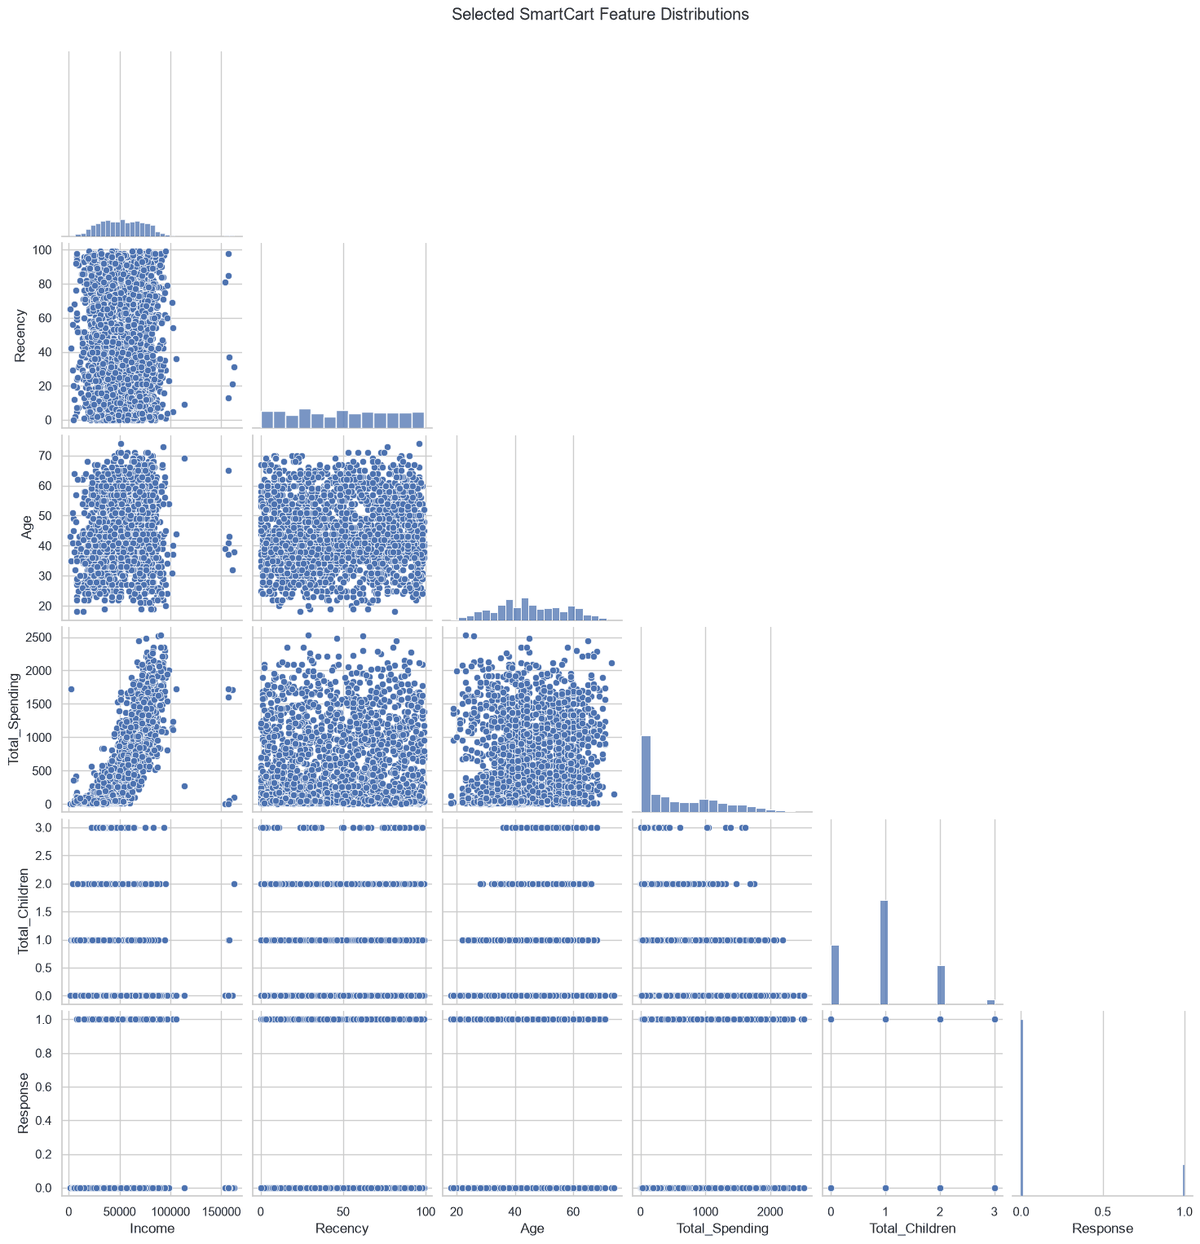

In [6]:
pairplot_columns = ["Income", "Recency", "Age", "Total_Spending", "Total_Children", "Response"]
pair_grid = sns.pairplot(df_cleaned[pairplot_columns], corner=True, diag_kind="hist")
pair_grid.fig.suptitle("Selected SmartCart Feature Distributions", y=1.02)
plt.show()

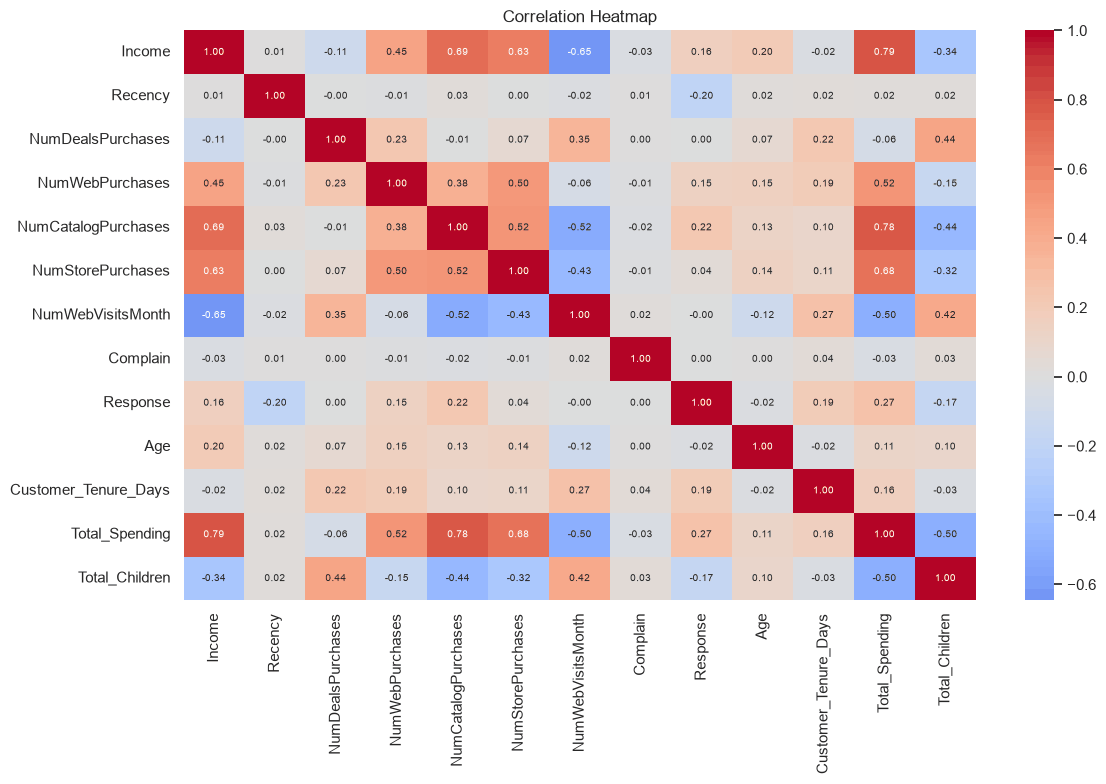

In [7]:
corr = df_cleaned.corr(numeric_only=True)

plt.figure(figsize=(12, 8))
sns.heatmap(corr, cmap="coolwarm", center=0, annot=True, fmt=".2f", annot_kws={"size": 7})
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

## 4. Build the model feature matrix

`Response` and `Complain` are held out of clustering and retained only for post-cluster profiling. This
avoids defining customer segments with the same campaign outcomes later used to describe them.

For encoding, all three education categories are retained, while one level of the binary living-status
feature is dropped to avoid counting the same binary distinction twice.

In [8]:
profile_df = df_cleaned.copy()
model_df = df_cleaned.drop(columns=["Response", "Complain"]).copy()

categorical_columns = ["Education", "Living_With"]
encoder = OneHotEncoder(
    drop="if_binary",
    handle_unknown="ignore",
    sparse_output=False,
)
encoded_values = encoder.fit_transform(model_df[categorical_columns])
encoded_df = pd.DataFrame(
    encoded_values,
    columns=encoder.get_feature_names_out(categorical_columns),
    index=model_df.index,
)

X = pd.concat([model_df.drop(columns=categorical_columns), encoded_df], axis=1)
if not np.isfinite(X.to_numpy(dtype=float)).all():
    raise ValueError("The model feature matrix contains missing or infinite values.")

print(f"Model matrix: {X.shape[0]:,} customers x {X.shape[1]} features")
display(X.head())

Model matrix: 2,236 customers x 15 features


,Income,Recency,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Age,Customer_Tenure_Days,Total_Spending,Total_Children,Education_Graduate,Education_Postgraduate,Education_Undergraduate,Living_With_Partner
0,58138.0,58,3,8,10,4,7,57,663,1617,0,1.0,0.0,0.0,0.0
1,46344.0,38,2,1,1,2,5,60,113,27,2,1.0,0.0,0.0,0.0
2,71613.0,26,1,8,2,10,4,49,312,776,0,1.0,0.0,0.0,1.0
3,26646.0,26,2,2,0,4,6,30,139,53,1,1.0,0.0,0.0,1.0
4,58293.0,94,5,5,3,6,5,33,161,422,1,0.0,1.0,0.0,1.0


In [9]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

## 5. PCA visualization

Three principal components provide a compact view of the data. Their explained-variance share is
reported explicitly; these components are not used as the clustering input.

,Explained variance
PC1,27.44%
PC2,12.41%
PC3,11.82%


Cumulative variance shown: 51.68%


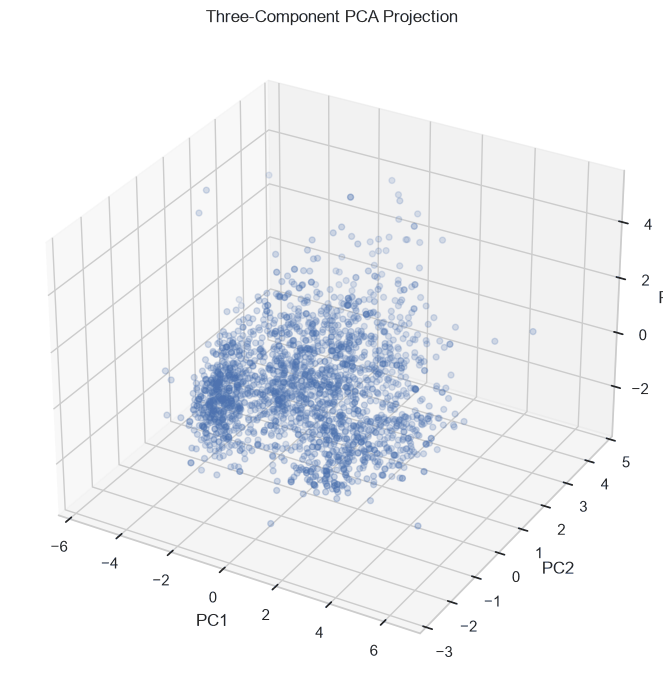

In [10]:
pca = PCA(n_components=3, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X_scaled)

explained_variance = pd.Series(
    pca.explained_variance_ratio_,
    index=["PC1", "PC2", "PC3"],
    name="Explained variance",
)
display(explained_variance.to_frame().style.format("{:.2%}"))
print(f"Cumulative variance shown: {explained_variance.sum():.2%}")

fig = plt.figure(figsize=(9, 7))
ax = fig.add_subplot(111, projection="3d")
ax.scatter(X_pca[:, 0], X_pca[:, 1], X_pca[:, 2], s=18, alpha=0.55)
ax.set(xlabel="PC1", ylabel="PC2", zlabel="PC3", title="Three-Component PCA Projection")
plt.tight_layout()
plt.show()

## 6. Select the number of clusters

The elbow method supplies the primary cluster-count recommendation. Silhouette scores are shown as a
secondary diagnostic: the most separated solution is not always the most useful or interpretable one.
All diagnostics below use the full standardized feature matrix.

In [11]:
k_values = list(range(1, MAX_CLUSTERS + 1))
wcss = []

for k in k_values:
    model = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=20)
    model.fit(X_scaled)
    wcss.append(model.inertia_)

knee = KneeLocator(k_values, wcss, curve="convex", direction="decreasing")
optimal_k = int(knee.elbow) if knee.elbow is not None else 4

silhouette_k_values = list(range(2, MAX_CLUSTERS + 1))
silhouette_scores = []
for k in silhouette_k_values:
    labels = KMeans(
        n_clusters=k,
        random_state=RANDOM_STATE,
        n_init=20,
    ).fit_predict(X_scaled)
    silhouette_scores.append(silhouette_score(X_scaled, labels))

best_silhouette_k = silhouette_k_values[int(np.argmax(silhouette_scores))]
print(f"Elbow-selected k: {optimal_k}")
print(f"Highest silhouette in the tested range: k={best_silhouette_k}")

Elbow-selected k: 4
Highest silhouette in the tested range: k=2


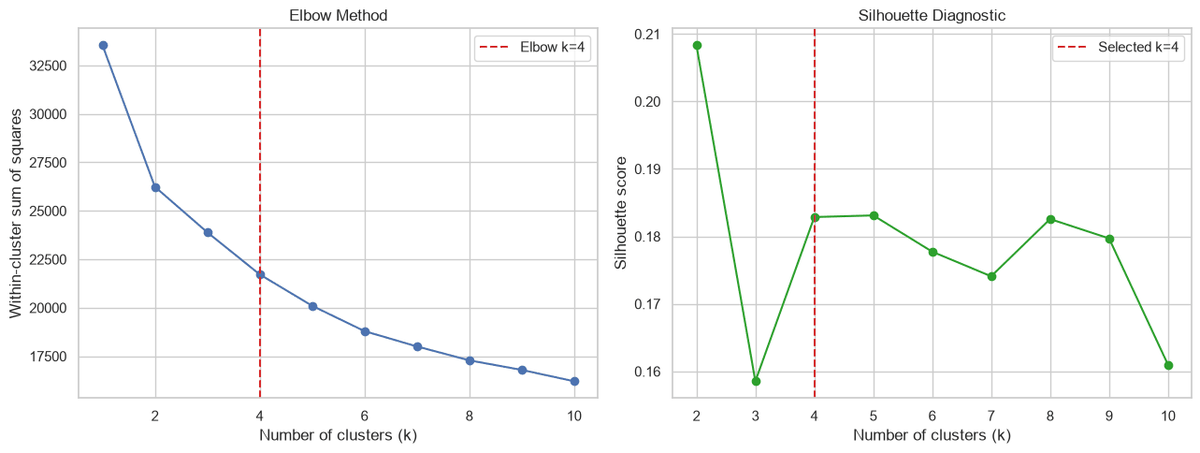

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].plot(k_values, wcss, marker="o")
axes[0].axvline(optimal_k, color="tab:red", linestyle="--", label=f"Elbow k={optimal_k}")
axes[0].set(xlabel="Number of clusters (k)", ylabel="Within-cluster sum of squares", title="Elbow Method")
axes[0].legend()

axes[1].plot(silhouette_k_values, silhouette_scores, marker="o", color="tab:green")
axes[1].axvline(optimal_k, color="tab:red", linestyle="--", label=f"Selected k={optimal_k}")
axes[1].set(xlabel="Number of clusters (k)", ylabel="Silhouette score", title="Silhouette Diagnostic")
axes[1].legend()

plt.tight_layout()
plt.show()

## 7. Compare clustering algorithms

K-Means and Ward-linkage agglomerative clustering are fitted with the same cluster count and evaluated
in the same standardized feature space. Higher silhouette and Calinski-Harabasz scores are better;
lower Davies-Bouldin scores are better.

In [13]:
n_clusters = optimal_k

kmeans = KMeans(
    n_clusters=n_clusters,
    random_state=RANDOM_STATE,
    n_init=20,
)
kmeans_labels = kmeans.fit_predict(X_scaled)

agglomerative = AgglomerativeClustering(n_clusters=n_clusters, linkage="ward")
agglomerative_labels = agglomerative.fit_predict(X_scaled)


def clustering_metrics(labels):
    return {
        "Silhouette": silhouette_score(X_scaled, labels),
        "Davies-Bouldin": davies_bouldin_score(X_scaled, labels),
        "Calinski-Harabasz": calinski_harabasz_score(X_scaled, labels),
    }


model_comparison = pd.DataFrame(
    {
        "K-Means": clustering_metrics(kmeans_labels),
        "Agglomerative": clustering_metrics(agglomerative_labels),
    }
).T
display(model_comparison.style.format("{:.3f}"))

,Silhouette,Davies-Bouldin,Calinski-Harabasz
K-Means,0.183,1.722,404.859
Agglomerative,0.169,1.917,347.973


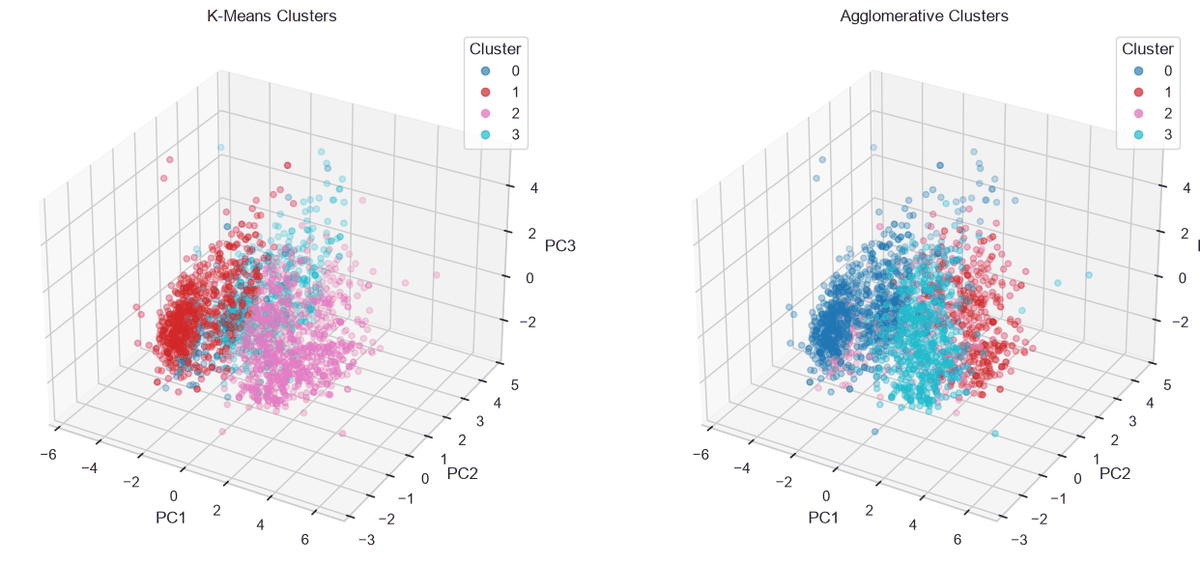

In [14]:
fig = plt.figure(figsize=(14, 6))

for position, (title, labels) in enumerate(
    [("K-Means", kmeans_labels), ("Agglomerative", agglomerative_labels)],
    start=1,
):
    ax = fig.add_subplot(1, 2, position, projection="3d")
    scatter = ax.scatter(
        X_pca[:, 0],
        X_pca[:, 1],
        X_pca[:, 2],
        c=labels,
        cmap="tab10",
        s=20,
        alpha=0.65,
    )
    ax.set(xlabel="PC1", ylabel="PC2", zlabel="PC3", title=f"{title} Clusters")
    ax.legend(*scatter.legend_elements(), title="Cluster", loc="best")

plt.tight_layout()
plt.show()

In [15]:
selected_algorithm = model_comparison["Silhouette"].idxmax()
selected_labels = (
    kmeans_labels if selected_algorithm == "K-Means" else agglomerative_labels
)

print(
    f"Selected model: {selected_algorithm} with {n_clusters} clusters "
    "(highest silhouette among the two candidates)."
)

Selected model: K-Means with 4 clusters (highest silhouette among the two candidates).


## 8. Profile the selected customer segments

The profiles use original business units, not standardized values. Campaign response and complaint
rates appear here only as descriptive outcomes; they were not used to create the segments.

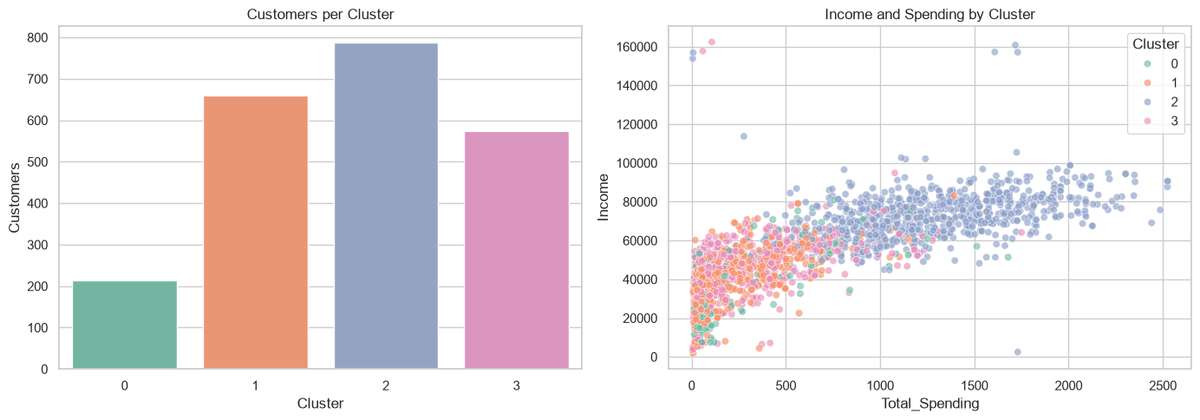

In [16]:
clustered_customers = profile_df.copy()
clustered_customers["Cluster"] = selected_labels
clustered_customers["Lives_With_Partner"] = (
    clustered_customers["Living_With"] == "Partner"
).astype(int)

palette = sns.color_palette("Set2", n_colors=n_clusters)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.countplot(data=clustered_customers, x="Cluster", hue="Cluster", palette=palette, legend=False, ax=axes[0])
axes[0].set_title("Customers per Cluster")
axes[0].set_ylabel("Customers")

sns.scatterplot(
    data=clustered_customers,
    x="Total_Spending",
    y="Income",
    hue="Cluster",
    palette=palette,
    alpha=0.65,
    ax=axes[1],
)
axes[1].set_title("Income and Spending by Cluster")

plt.tight_layout()
plt.show()

In [17]:
cluster_summary = clustered_customers.groupby("Cluster").agg(
    Customers=("Income", "size"),
    Average_Income=("Income", "mean"),
    Average_Spending=("Total_Spending", "mean"),
    Average_Recency=("Recency", "mean"),
    Average_Age=("Age", "mean"),
    Average_Children=("Total_Children", "mean"),
    Response_Rate=("Response", "mean"),
    Complaint_Rate=("Complain", "mean"),
    Partner_Share=("Lives_With_Partner", "mean"),
)
cluster_summary.insert(1, "Share", cluster_summary["Customers"] / len(clustered_customers))

percentage_columns = ["Share", "Response_Rate", "Complaint_Rate", "Partner_Share"]
summary_styler = cluster_summary.style.format(
    {
        "Customers": "{:,.0f}",
        "Share": "{:.1%}",
        "Average_Income": "{:,.0f}",
        "Average_Spending": "{:,.0f}",
        "Average_Recency": "{:.1f}",
        "Average_Age": "{:.1f}",
        "Average_Children": "{:.2f}",
        "Response_Rate": "{:.1%}",
        "Complaint_Rate": "{:.1%}",
        "Partner_Share": "{:.1%}",
    }
)
display(summary_styler)

education_mix = pd.crosstab(
    clustered_customers["Cluster"],
    clustered_customers["Education"],
    normalize="index",
)
display(education_mix.style.format("{:.1%}").set_caption("Education mix within each cluster"))

,Customers,Share,Average_Income,Average_Spending,Average_Recency,Average_Age,Average_Children,Response_Rate,Complaint_Rate,Partner_Share
Cluster,,,,,,,,,,
0,214,9.6%,"35,426",245,49.1,38.8,0.99,6.1%,0.9%,69.2%
1,660,29.5%,"38,077",195,50.0,43.2,1.26,9.2%,1.4%,64.5%
2,787,35.2%,"73,211","1,277",50.0,46.9,0.41,23.0%,0.9%,62.1%
3,575,25.7%,"44,935",294,46.9,47.2,1.32,13.7%,0.3%,65.9%


Education,Graduate,Postgraduate,Undergraduate
Cluster,,,
0,0.0%,0.0%,100.0%
1,100.0%,0.0%,0.0%
2,59.2%,35.6%,5.2%
3,0.0%,100.0%,0.0%


## 9. Interpretation and limitations

- Cluster labels are descriptive, not causal. They should support exploration and campaign design,
  not determine access, eligibility, or other high-impact decisions.
- The observations are historical (customer enrollment ends in 2014), so behavior may not represent
  current customers or market conditions.
- Results depend on the selected variables, scaling, outlier rules, and cluster count. Revalidate the
  profiles on newer data before operational use.
- The campaign response rate is an out-of-model profiling measure. Differences between clusters are
  associations and do not prove that cluster membership causes response.